# Subplots and presentation style — Tips
## 1. Task
Build one 2x2 presentation-ready figure that summarizes restaurant bills and tips.
## 2. Data

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

(2, 2)


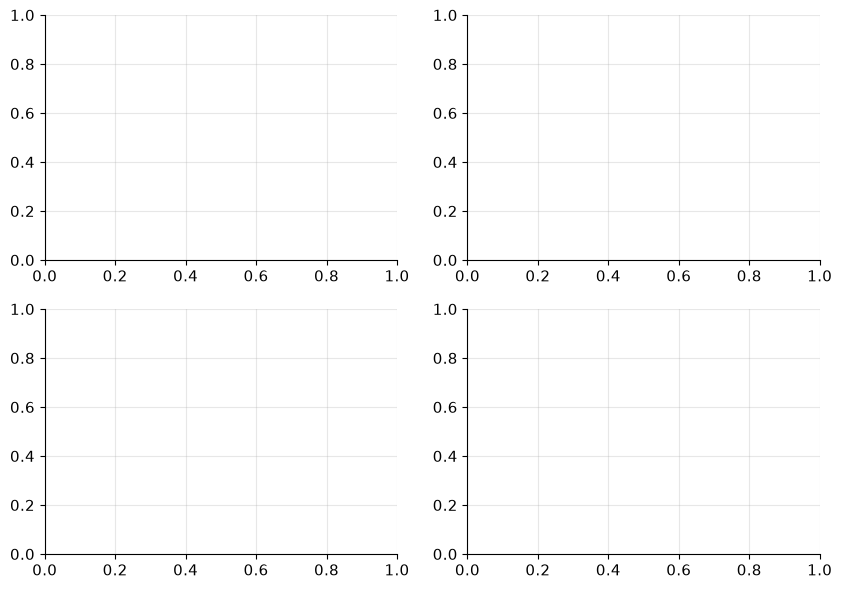

In [14]:
df = sns.load_dataset('tips')
df['tip_pct'] = df['tip'] / df['total_bill']*100

fig, axes = plt.subplots(2, 2, figsize=(10,7))
print(axes.shape)
plt.show()

## fillup grid

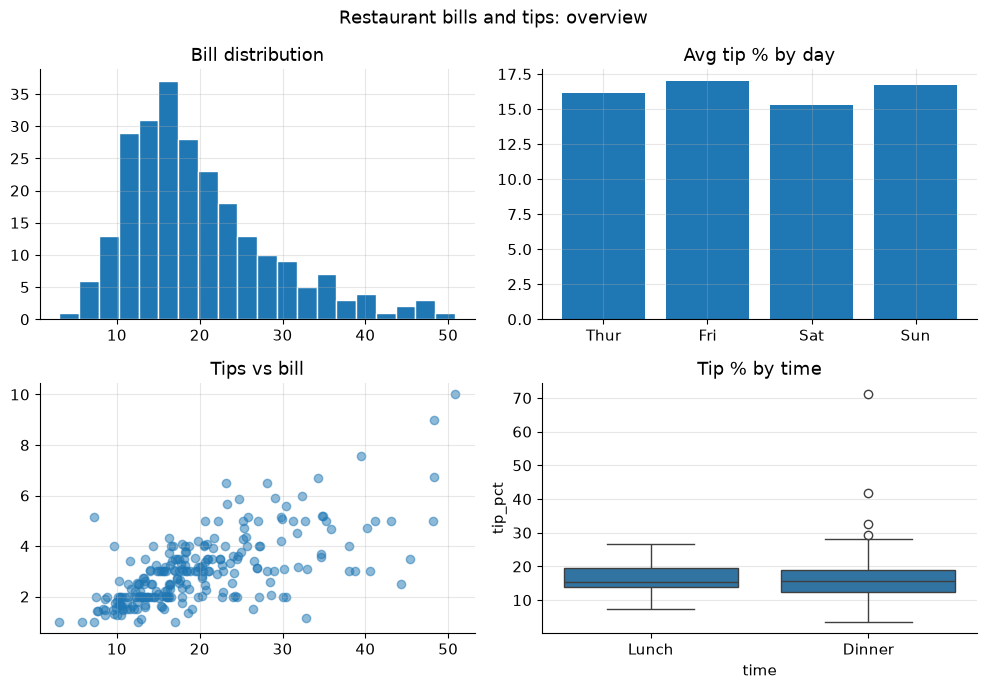

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10,7))

axes[0,0].hist(df['total_bill'], bins=20, edgecolor='white')
axes[0,0].set_title('Bill distribution')

pct_by_day =  df.groupby('day', observed=True)['tip_pct'].mean()
axes[0,1].bar(pct_by_day.index, pct_by_day.values)
axes[0,1].set_title('Avg tip % by day')

axes[1,0].scatter(df['total_bill'], df['tip'], alpha=0.5)
axes[1,0].set_title('Tips vs bill')

sns.boxplot(data=df, x='time', y='tip_pct', ax=axes[1,1])
axes[1,1].set_title('Tip % by time')

fig.suptitle('Restaurant bills and tips: overview')
fig.tight_layout()
plt.show()

## style and signs

In [16]:
plt.rcParams.update({
    'font.size':11,
    'axes.spines.top':False,
    'axes.spines.right':False,
    'axes.grid':True,
    'grid.alpha':0.3,
})

In [17]:
axes[0, 0].set_xlabel("Total bill, $");   axes[0, 0].set_ylabel("Number of bills")
axes[0, 1].set_xlabel("Day");             axes[0, 1].set_ylabel("Tip, % of bill")
axes[1, 0].set_xlabel("Total bill, $");   axes[1, 0].set_ylabel("Tip, $")
axes[1, 1].set_xlabel("Time");            axes[1, 1].set_ylabel("Tip, % of bill")

Text(506.77598741319434, 0.5, 'Tip, % of bill')

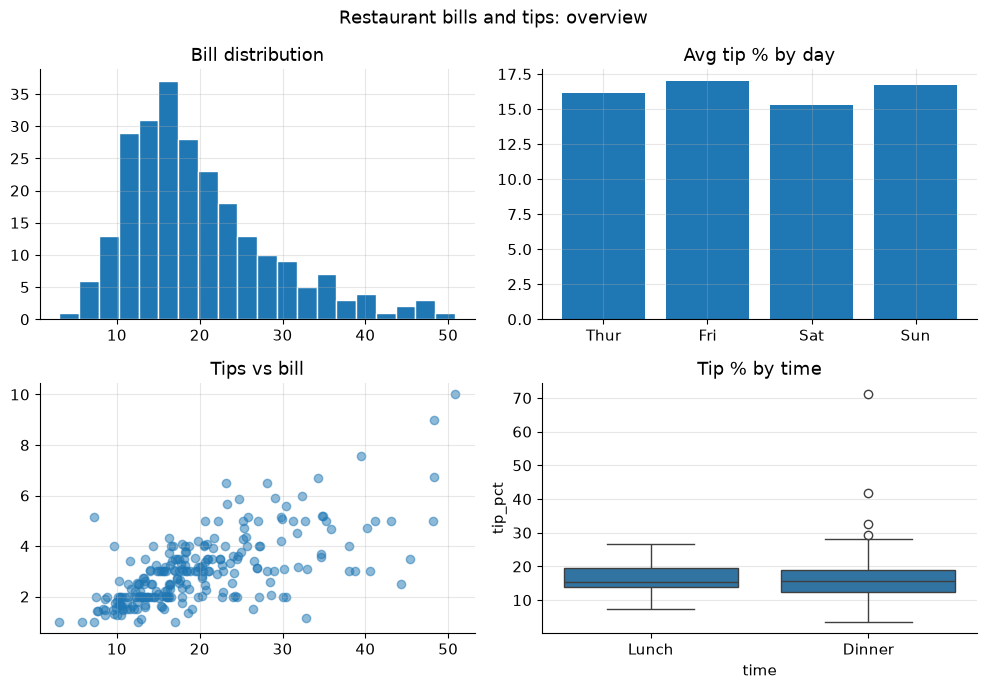

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(10,7))

axes[0,0].hist(df['total_bill'], bins=20, edgecolor='white')
axes[0,0].set_title('Bill distribution')

pct_by_day =  df.groupby('day', observed=True)['tip_pct'].mean()
axes[0,1].bar(pct_by_day.index, pct_by_day.values)
axes[0,1].set_title('Avg tip % by day')

axes[1,0].scatter(df['total_bill'], df['tip'], alpha=0.5)
axes[1,0].set_title('Tips vs bill')

sns.boxplot(data=df, x='time', y='tip_pct', ax=axes[1,1])
axes[1,1].set_title('Tip % by time')

fig.suptitle('Restaurant bills and tips: overview')
fig.tight_layout()
plt.show()

## save

In [19]:
fig.savefig('overview.png', dpi=300, bbox_inches='tight')

## experiment

In [20]:
axes[0, 0].set_title("Most bills are $10–20")
axes[0, 1].set_title("Tip % barely depends on the day (15–17%)")
axes[1, 0].set_title("Bigger bill — bigger tip")
axes[1, 1].set_title("Lunch and dinner tip % are similar")

fig.suptitle("Tips are a stable ~16% of the bill", fontsize=14, fontweight="bold")

Text(0.5, 0.98, 'Tips are a stable ~16% of the bill')

In [21]:
fig.savefig("overview_insights.png", dpi=150, bbox_inches="tight")

## 5. What I learned
- `plt.subplots(2, 2)` creates a grid; each chart is `axes[row, col]`. seaborn draws into a cell via `ax=`. `suptitle` is for the whole figure, `set_title` for one chart.
- `rcParams` sets one style for all charts (font, grid, no extra frame lines); every axis needs a label with units; `savefig` goes before `plt.show()`.
- Experiment: titles that state the conclusion ("Tips are a stable ~16%") make a slide readable in seconds; descriptive titles are for working notebooks.